# Plot all distinct colors

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

def get_colors(image_path):
    image = Image.open(image_path).convert("RGB")  # Open and convert image to RGB
    colors = image.getcolors(maxcolors=1000000)  # Extract colors from image
    
    unique_colors = set()
    color_info = []
    
    for count, color in colors:
        hex_code = '#%02x%02x%02x' % color  # Convert RGB to hex
        unique_colors.add(hex_code)
        color_info.append(hex_code)
    
    return color_info

def plot_colors(color_info, n=5):
    """Swatches, n per row, each with its hex code written underneath."""
    cols = min(n, len(color_info))
    rows = -(-len(color_info) // n)  # ceil division
    fig, ax = plt.subplots(figsize=(cols * 1.5, rows * 1.5))
    ax.set_xlim(0, cols)
    ax.set_ylim(0, rows)
    ax.set_aspect("equal")
    ax.axis("off")

    for i, hex_code in enumerate(color_info):
        col = i % n
        y = rows - 1 - i // n  # top row first
        # swatch fills the top of the cell, label sits in the strip below it
        ax.add_patch(plt.Rectangle((col + 0.05, y + 0.3), 0.9, 0.65,
                                   facecolor=hex_code, edgecolor="lightgray", linewidth=0.5))
        ax.text(col + 0.5, y + 0.15, hex_code, ha="center", va="center", fontsize=10, family="monospace")

    plt.show()


['#893e0f', '#883e0f', '#8b3c0f', '#893c0f', '#4b324f', '#b8691d', '#b6691d', '#b8681d', '#b6681d', '#ecbb7c', '#edba7c', '#ecba7c', '#ebba7c', '#ecb97c', '#ebb97c', '#b76a1c', '#b66a1c', '#b9691c', '#edbb7b', '#ecbb7b', '#eabb7b', '#edba7b', '#ecba7b', '#ebba7b', '#edb97b', '#ecb97b', '#ebb97b', '#b8691b', '#b6691b', '#b9681b', '#b8681b', '#b6681b', '#f0d9ba', '#ecbb7a', '#eabb7a', '#edba7a', '#ecba7a', '#ebba7a', '#ecb97a', '#b96a1a', '#b76a1a', '#b66a1a', '#b9691a', '#f5ead9', '#b86919', '#b66919', '#b96819', '#b86819', '#b76819', '#b96a18', '#b76a18', '#b66a18', '#b96918', '#281728', '#b8a3c7', '#baa2c7', '#b9a2c7', '#b7a2c7', '#baa1c7', '#b9a1c7', '#b8a1c7', '#baa2c6', '#b9a2c6', '#b7a2c6', '#baa1c6', '#b9a1c6', '#b8a1c6', '#ede7f5', '#baa3c5', '#b8a3c5', '#b7a3c5', '#b9a1c5', '#b8a1c5', '#311e15', '#baa3c4', '#b8a3c4', '#b7a3c4', '#baa2c4', '#b9a2c4', '#b7a2c4', '#baa1c4', '#883b14', '#d19a63', '#d39963', '#d19963', '#d49863', '#d39763', '#d29763', '#893e13', '#883e13', '#883d13'

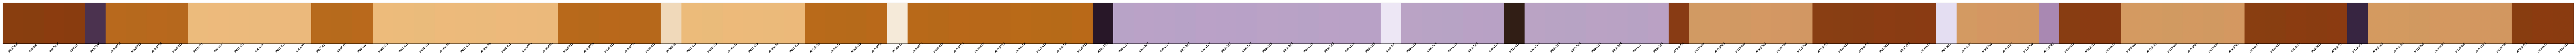

In [6]:
IMAGE_PATH = "/Users/sophial/Documents/githubs/ReassemblingOsiris/palettes/palette3.png"

colors = get_colors(IMAGE_PATH)
print(colors)
plot_colors(colors)

# Visualize color replacements

In [ ]:
IMAGE_PATH = "/Users/sophial/Downloads/RPG_fantasy_tilesets/RPG_exterior.png"
# Define the color mapping as a dictionary
COLOR_MAP = {
    "#e0f8cf":"#e5d3b3",      
    "#86c06c":"#b99976",      
    "#071821":"#664229", 
    "#306850":"#987554"
}

fig, ax = plt.subplots(len(COLOR_MAP), 2, figsize=(4, len(COLOR_MAP) * 2))
ax = ax.reshape(len(COLOR_MAP), 2)
for i, (orig, mapped) in enumerate(COLOR_MAP.items()):
    for j, color in enumerate([orig, mapped]):
        ax[i, j].add_patch(plt.Rectangle((0, 0), 1, 1, color=color))
        ax[i, j].set_title(color, fontsize=10)
        ax[i, j].axis("off")
plt.tight_layout()
plt.show()

# Replace mapped colors

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

def hex_to_rgb(hex_color):
    """Converts hexadecimal color representation to RGB."""
    hex_color = hex_color.strip("#")
    return tuple(int(hex_color[i:i + 2], 16) for i in (0, 2, 4))


def apply_color_mapping(image_path, color_map):
    image = Image.open(image_path)
    width, height = image.size

    pixels = image.load()

    # Iterate through each pixel
    for y in range(height):
      for x in range(width):
        # r, g, b, t = pixels[x, y] # for transparent images
        r, g, b = pixels[x, y]
        hex_color = "#{:02x}{:02x}{:02x}".format(r, g, b)
        if hex_color in color_map:
          new_hex_color = color_map[hex_color]
          new_r, new_g, new_b = hex_to_rgb(new_hex_color)
          pixels[x, y] = (new_r, new_g, new_b)

    # Save the modified image
    plt.imshow(image)
    return image


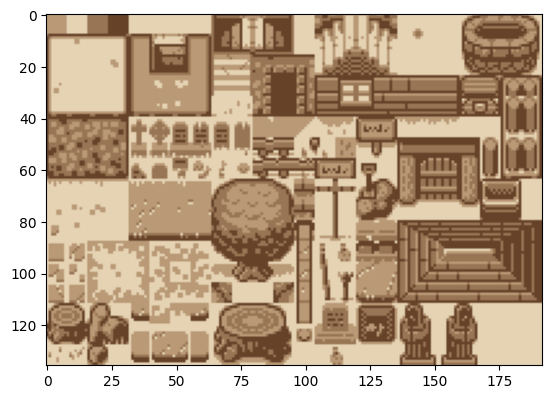

In [ ]:
# Apply the color mapping
image = apply_color_mapping(IMAGE_PATH, COLOR_MAP)
image.save("modified_image.png")